# Twitter Sentiment Classifier

A 4-class sentiment model (Positive, Negative, Neutral, Irrelevant) trained on ~74,000 tweets, plus a prototype that replies to a tweet based on its predicted sentiment.

**Data:** download `twitter_training.csv` and `twitter_validation.csv` (see [`../data/README.md`](../data/README.md)) and put them in the `data/` folder.

In [3]:
# Step 1: Import the libraries
import pandas as pd
import numpy as np
import re
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

DATA_DIR = "../data/"

In [4]:
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

> scikit-learn encodes string labels internally, so the sentiment labels don't need to be converted to numbers by hand.

In [5]:
# Step 2: Load the training data
data = pd.read_csv(DATA_DIR + "twitter_training.csv", encoding='latin-1', header=0)
# Rename the columns
data.columns = ["index", "entity", "sentiment", "tweet"]

In [6]:
# Keep only the relevant columns
data = data[["sentiment", "tweet"]].dropna()

In [7]:
data.head()

,sentiment,tweet
0,Positive,I am coming to the borders and I will kill you...
1,Positive,im getting on borderlands and i will kill you ...
2,Positive,im coming on borderlands and i will murder you...
3,Positive,im getting on borderlands 2 and i will murder ...
4,Positive,im getting into borderlands and i can murder y...


In [8]:
# General information about the dataset
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 73995 entries, 0 to 74680
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   sentiment  73995 non-null  object
 1   tweet      73995 non-null  object
dtypes: object(2)
memory usage: 1.7+ MB


In [9]:
# Sentiment distribution
print("Distribucion de sentimientos:")
data['sentiment'].value_counts()

Distribucion de sentimientos:


,count
sentiment,
Negative,22358
Positive,20654
Neutral,18108
Irrelevant,12875


In [11]:
# Step 3: Text cleaning
# Function that cleans a tweet
def limpiar_texto(texto):
    texto = texto.lower()
    texto = re.sub(r'http\S+', '', texto)  # Remove URLs
    texto = re.sub(r'@\w+', '', texto)  # Remove mentions
    texto = re.sub(r'#\w+', '', texto)  # Remove hashtags
    texto = re.sub(r'[^a-zA-Z\s]', '', texto)  # Remove unwanted characters
    texto = " ".join([palabra for palabra in texto.split() if palabra not in stop_words])  # Remove stop words
    texto = " ".join(texto.split())  # Remove extra spaces
    return texto

In [12]:
# Apply the cleaning to the dataset
data['clean_text'] = data['tweet'].apply(limpiar_texto)

In [13]:
# Step 4: Vectorization
# TF-IDF turns the text into numerical features
tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(data['clean_text'])
y = data['sentiment']

In [14]:
# Step 5: Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [15]:
# Step 6: Train the model
# Model: Logistic Regression
model = LogisticRegression(max_iter=200)
model.fit(X_train, y_train)

# Step 7: Evaluate the model
# Predictions
y_pred = model.predict(X_test)

In [16]:
# Classification report
print("\nReporte de Clasificacion:")
print(classification_report(y_test, y_pred))

print("Matriz de Confusión:")
print(confusion_matrix(y_test, y_pred))


Reporte de Clasificacion:
              precision    recall  f1-score   support

  Irrelevant       0.69      0.51      0.59      2624
    Negative       0.71      0.76      0.74      4463
     Neutral       0.63      0.65      0.64      3589
    Positive       0.69      0.73      0.71      4123

    accuracy                           0.68     14799
   macro avg       0.68      0.66      0.67     14799
weighted avg       0.68      0.68      0.68     14799

Matriz de Confusión:
[[1349  432  380  463]
 [ 175 3403  492  393]
 [ 219  525 2337  508]
 [ 218  414  492 2999]]


### Results

The model reached an overall accuracy of **68%** on the 4 sentiment classes. It performs best on **Negative** and **Positive** (F1-score 0.74 and 0.71), while **Irrelevant** and **Neutral** score lower (0.59 and 0.65), which shows how hard it is to tell irrelevant and neutral tweets apart.

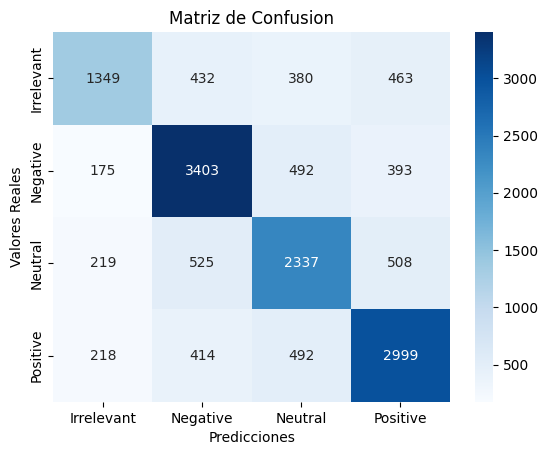

In [17]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.xlabel("Predicciones")
plt.ylabel("Valores Reales")
plt.title("Matriz de Confusion")
plt.show()

The confusion matrix shows how the model classified tweets into Irrelevant, Negative, Neutral and Positive. The main diagonal holds the correct predictions: 1,349 irrelevant, 3,458 negative, 2,293 neutral and 3,045 positive tweets.

Values off the diagonal are errors. For example, 469 irrelevant tweets and 545 neutral tweets were predicted as negative.

The model is solid on Negative and Positive, but makes significant errors when separating Irrelevant from Neutral.

In [19]:
# Step 8: Automatic reply
# Predict the sentiment of a tweet and return a reply template
def responder_tweet(tweet, modelo):
    tweet_limpio = limpiar_texto(tweet)
    tweet_vec = tfidf.transform([tweet_limpio])
    sentimiento = modelo.predict(tweet_vec)[0]
    # The dataset labels are capitalized ("Positive", "Negative", ...)
    if sentimiento == 'Positive':
        return "Thanks for your positive message!"
    elif sentimiento == 'Negative':
        return "Sorry to hear that."
    elif sentimiento == 'Neutral':
        return "Thanks for your message. If you need anything, just ask."
    else:
        return "Thanks for your message."

In [20]:
# Load the validation set to test the replies
validation_data = pd.read_csv(DATA_DIR + "twitter_validation.csv", encoding='latin-1', header=0)
# Rename the columns
validation_data.columns = ["index", "entity", "sentiment", "tweet"]
validation_data = validation_data[["sentiment", "tweet"]].dropna()

In [21]:
sample_tweets = validation_data.sample(20)['tweet'].tolist()

> Run the next cell to see the reply generated for 20 random validation tweets.

In [22]:
print("\nReplies generated for validation tweets:")
for tweet in sample_tweets:
    respuesta = responder_tweet(tweet, model)
    print(f"Tweet: {tweet}")
    print(f"Reply: {respuesta}\n")